# 08a The preferred slip model: 3D elastic structure (SFSVM), PyLith Green's functions

```
Author: Danielle Lindsay
Environment: environment.yml. Runs after 07a. About 45 min (30 solves for the L-curve, 100 for the Monte Carlo).
PyLith is not run here: the Green's functions are read from the stored G matrix of the PyLith run.
```

**What this notebook does.** The paper's slip model, with the settings of `model_config.py`: the PyLith Green's
functions of `model_config.gf_run` (3D SFSVM elastic structure, fault dipping 70 deg W; the vertical fault on the
same mesh is a sensitivity test), the samples and noise model of 07a, equal weights, a plane solved jointly,
slip >= 0 and the CSI exponential prior at the L-curve corner, no surface constraint. Then the fit (maps and profiles
of G x slip at the samples), the size (potency, Mw at 30 GPa and at the slip-weighted harmonic SFSVM rigidity), the
depths above which 50 % / 90 % of the potency lie, the comparison with the homogeneous model of 07a, a Monte Carlo of
correlated noise, and the stress drop from the fixed-depth scan.

**Inputs**: 07a `model_data.npz`, `homogeneous_model.npz`, `homogeneous_lcurve.csv`; the PyLith products listed in [2];
06 `fig2_inputs.npz` (profile lines); 04 `section_lengths.csv`, `event_fraction_by_crossing.csv`; the stored outputs
of `scripts/sensitivity/` listed in `model_config.archived` (the '70 W' fine-mesh dip row, for a check, and the
fixed-depth scan).

**Outputs** (`outputs/08a_3d_model/`): `selected_lcurve.csv`, `selected_model.npz` (slip, prediction, plane,
residual, crossings steps: Fig 2 reads it), `rigidity_beside_fault.csv`, `model_comparison.csv`,
`montecarlo_realisations.csv`, `montecarlo_summary.csv`, `stress_drop.csv`, `near_fault_deflection.csv`, `08a_selected_stats.txt`.
**Figures** (`Figures_<fig_date>/`): `figS_model_lcurve`, `figS_model_slip`, `figS_model_fit_maps`,
`figS_model_profiles`, `figS_model_montecarlo`, `figS_pylith_materials_sfcvm_v26` (`scripts/model_plots/plot_materials.py`).
**Registry keys** `08a_*`.

**What to check**
- [2] Every PyLith file exists, including the run's completion marker.
- [5] Check: the corners and every number equal the '70 W' fine-mesh dip row of `scripts/sensitivity/sensitivity_rows.py`.
- [6] Mw at 30 GPa and at the harmonic SFSVM rigidity; depth50 / depth90.
- [10] The Monte Carlo spread, and its mean against the model.
- [11] Check: the best row of the fixed-depth scan is re-solved here and equals the stored scan.

## [1] Imports, settings and the number registry

In [1]:
## [1]
import os
import sys
import time
import warnings

import numpy as np
import pandas as pd
import pyproj
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.collections import PolyCollection
from cmcrameri import cm as cmc

warnings.filterwarnings("ignore", category=DeprecationWarning)   # library noise only; numerical warnings stay visible
warnings.filterwarnings("ignore", category=FutureWarning)
from TulePond_filepaths import common_paths, repo_dir, paths_out, paths_sfcvm, model_crs
import insar_utils as utils
import model_config as cfg                          # the settings of the slip models
import model_utils                                  # the modelling functions

notebook = "08a_3d_model"
out_dir = paths_out[notebook]
dir_07a = paths_out["07a_uniform_model"]
field_dir = paths_out["06_event_field_geometry"]
events_dir = paths_out["04_event_detection"]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
made = time.strftime("%Y-%m-%d %H:%M")
creep_lo_km, creep_hi_km = cfg.sse_section_km()
band_lo_km, band_hi_km = cfg.band90_km()
model_data_file = os.path.join(dir_07a, "model_data.npz")
homogeneous_file = os.path.join(dir_07a, "homogeneous_model.npz")
fig2_inputs_file = os.path.join(field_dir, "fig2_inputs.npz")
crossings_file = os.path.join(events_dir, "event_fraction_by_crossing.csv")
REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(model_data_file, homogeneous_file, os.path.join(dir_07a, "homogeneous_lcurve.csv"), fig2_inputs_file, crossings_file,
           os.path.join(events_dir, "section_lengths.csv"), os.path.join(events_dir, "creep_events.csv"), cfg.gf_files["G"],
           cfg.archived["sensitivity_rows_20261030"], cfg.archived["depth_scan"])
OKABE = dict(blue="#0072B2", orange="#E69F00", vermillion="#D55E00", purple="#CC79A7", black="#000000", grey="#999999")
utils.mpl_paper_style(base=7)
cm = 1 / 2.54
print("\n".join(cfg.summary()))

Registry for 08a_3d_model: run e90ab70c, git 7e6193e
forward model gf_shallow_sfcvm_order2 (PyLith 5.0.2, order 2, shallow mesh, SFSVM v26.0 aligned, no Vs floor, no cap)
data: swath 4 km, km 52-67, quadtree 2 -> 30 m; near-trace cut 60 m
noise: semivariogram beyond 5 km on a 15 km swath, pairs < 8 km
weighting: diagonal, nugget^2 / N^0 (equal weights); reference frame '1,x,y' solved jointly
prior: CSI exponential, lambda (0.1, 0.05) km (effective 0.2 / 0.1 km); slip >= 0; surface constraint OFF
sigma: own L-curve corner on 21 base values + 9 around the corner
SSE section km 56.30-62.20; 90 % band km 58.20-59.80 (04 section_lengths.csv); near field +/-500 m; mu_ref 30 GPa


## [2] The PyLith files of the Green's functions

The inputs and outputs of the PyLith 5.0.2 run `model_config.gf_run` (basis order 2), with paths: the mesh and its
report, the cfg files (`pylith/cfg/`), the SFSVM material database and the grid it was written from, the impulse
database, the output points (the samples of 07a), the command, the run log and completion marker, the raw outputs, and
the G matrix assembled from them (`model_utils.build_G`: impulse -> vertex, output point -> sample, projection on the
fault-parallel look vector, right-lateral sign). See `pylith/README.md`. Nothing is run here.

In [2]:
## [2]
pylith_files = []
for role in ("mesh", "mesh_report", "material_db", "material_grid", "impulse_db", "points", "log", "done_marker", "G"):
    pylith_files.append((role, cfg.gf_files[role]))
for path in cfg.gf_files["cfg"]:
    pylith_files.append(("cfg", os.path.join(repo_dir, path)))
for path in cfg.gf_files["outputs"]:
    pylith_files.append(("output", path))
for role, path in pylith_files:
    assert os.path.exists(path), f"missing PyLith file ({role}): {path}"
    size_mb = os.path.getsize(path) / 1e6
    print(f"{role:13s} {size_mb:9.1f} MB  {path}")
print(f"command (from the data root, queued by {cfg.gf_files['queue_script']}):\n  {cfg.gf_files['command']}")
with open(cfg.gf_files["mesh_report"]) as report:
    print("mesh report:", "".join(report.readlines()[:8]))

mesh               23.3 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_inputs/mesh/mesh_vertical_tet_shallow.msh
mesh_report         0.0 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_inputs/mesh/mesh_vertical_tet_shallow_report.txt
material_db       223.8 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_SFCVM/spatialdb/mat_sfcvm_v26-0_aligned_nocap.spatialdb
material_grid       7.4 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_SFCVM/spatialdb/sfcvm_v26-0_aligned_nocap_grid.npz
impulse_db          0.0 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_inputs/spatialdb/impulses_km54-65_z3000.spatialdb
points              0.1 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_inputs/points/insar_points.txt
log                 1.6 MB  /Users/dlindsay/work/proj_TulePond_DISP/modeling_SFCVM/runs/gf_shallow_sfcvm_order2.log
done_marker         0.0 MB  /Users/dlindsay/work/proj_TulePond_DISP/runs_done_2026-10-25/gf_shallow_sfcvm_order2
G                  64.7 MB  /U

## [3] The data and the inversion set-up

The samples of 07a (`model_data.npz`, rebuilt as a `csi.insar` set by `model_utils.samples_from_arrays`) and its noise
model. `model_utils.tent_model_setup` reads the stored G (`load_G`; built from the PyLith output by `build_G`,
asserted to be on these samples and at this strike), the tent fault and its CSI template, `keep` (samples 60 m or
more from the trace) and the near-field masks (within 500 m west / east, in the SSE section). Data covariance: the
nugget variance for every fitted sample (equal weights).

In [3]:
## [3]
model_data = np.load(model_data_file)
field_fingerprint = model_utils.field_fingerprint(os.path.join(field_dir, "fp_maps.npz"))
assert str(model_data["field_fingerprint"]) == field_fingerprint, "07a's model data were made from another 06 field: re-run 07a"
frame_lonlat = tuple(model_data["frame_lonlat"])
strike_deg = float(model_data["strike_deg"])
look = model_data["look"]
cov_p = model_data["cov_p"]
assert float(model_data["nugget_power"]) == cfg.nugget_power
profile_lats = pd.read_csv(common_paths["fault_profiles"]).ft_lat.values
trace = model_utils.model_trace(model_data["trace_lonlat"], -90.0, 90.0, frame_lonlat, profile_lats,
                                every_km=float(model_data["trace_every_km"]))
trace_xy_m = (trace["x_km"] * 1e3, trace["y_km"] * 1e3)
samples = model_utils.samples_from_arrays("fault-parallel samples", model_data["sample_lon"], model_data["sample_lat"],
                                          model_data["sample_x_km"], model_data["sample_y_km"], model_data["data_mm"],
                                          model_data["wgt"], look, frame_lonlat, cov_p, cfg.nugget_power)
setup = model_utils.tent_model_setup({"sfcvm": cfg.gf_run}, str(model_data["points_default"]), strike_deg,
                                     {"sfcvm": (cfg.gf_pylith_output_dir, cfg.gf_gf_dir)}, cfg.km_window, creep_lo_km, creep_hi_km,
                                     trace_xy_m, frame_lonlat, model_crs, profile_lats, cfg.near_trace_cut_km, cfg.near_field_km,
                                     trace["km_pp"])
G = setup["G"]["sfcvm"]
tents = setup["tents"]
keep, west_near, east_near = setup["keep"], setup["west_near"], setup["east_near"]
signed_d_km, sample_km_pp = setup["signed_d_km"], setup["sample_km_pp"]
assert np.array_equal(setup["points"]["lon"], model_data["sample_lon"]), "G is not on 07a's samples"
Cd = model_utils.data_cd(cfg.weighting, samples, cov_p, cfg.nugget_power, keep=keep)
print(f"G {G.shape} (samples x tents), max |G| {np.abs(G).max():.3f} m/m; {keep.sum()} fitted samples of {keep.size}; "
      f"near field {west_near.sum()} west / {east_near.sum()} east; sample sd {np.sqrt(cov_p[0]):.3f} mm (nugget)")


def solve_3d(sigma, vel=None):
    """The 3D model at one sigma (model_utils.invert_tents); vel replaces the data."""
    return model_utils.invert_tents(setup["template"], samples, G, Cd, None, None, sigma, cfg.lam_xz_km, frame_lonlat,
                                    use_surface=cfg.use_surface, vel_insar=vel, name=f"3D sigma {sigma:.3f}", ramp_spec=cfg.ramp_spec)

G (2386, 3373) (samples x tents), max |G| 0.560 m/m; 1787 fitted samples of 2386; near field 366 west / 334 east; sample sd 0.903 mm (nugget)


## [4] The rigidity beside the fault

The shear modulus used by PyLith (`-elastic_info.h5`; materials basis order 1: the cell mean of its vertex values) is
compared with the SFSVM grid it was read from (median difference < 5 % asserted), and the cell next to each fault
triangle on each side is taken (`model_utils.mu_beside_fault`). The rigidity of a fault between two materials is the
harmonic mean 2 mu_W mu_E / (mu_W + mu_E) (Vavrycuk 2013; `model_utils.harmonic_mean_rigidity`); Mw with it uses each
triangle's own value (the slip-weighted harmonic SFSVM rigidity).

In [4]:
## [4]
elastic_info = os.path.join(cfg.gf_pylith_output_dir, f"{cfg.gf_run}-elastic_info.h5")
mu_mean, mu_west, mu_east, mu_rel_median = model_utils.mu_beside_fault(elastic_info, cfg.sfcvm_grid_npz, tents, cfg.gf_run)
assert mu_rel_median < 0.05, "PyLith's cell rigidity differs from the SFSVM grid by more than 5 % (median)"
mu_harmonic = model_utils.harmonic_mean_rigidity(mu_west, mu_east)
rigidity = pd.DataFrame(dict(tri_km=tents.tri_km, tri_depth_m=tents.tri_depth_m, tri_area_m2=tents.tri_area,
                             mu_west_gpa=mu_west / 1e9, mu_east_gpa=mu_east / 1e9, mu_harmonic_gpa=mu_harmonic / 1e9))
rigidity.to_csv(os.path.join(out_dir, "rigidity_beside_fault.csv"), index=False)
top_section = (tents.tri_depth_m < 100) & (tents.tri_km >= creep_lo_km) & (tents.tri_km <= creep_hi_km)
print(f"SSE section, top 100 m: median mu west {np.median(mu_west[top_section]) / 1e9:.3f}, east "
      f"{np.median(mu_east[top_section]) / 1e9:.3f}, harmonic {np.median(mu_harmonic[top_section]) / 1e9:.3f} GPa")

gf_shallow_sfcvm_order2: PyLith cell mu vs grid at centroids (302988 cells in the fine box, top 1.5 km): median |rel diff| 0.000, 90th pct 0.189; PyLith mu range 0.039-64.5 GPa


gf_shallow_sfcvm_order2: fault-adjacent mu, top 100 m median: west 0.706, east 1.041 GPa
SSE section, top 100 m: median mu west 0.635, east 0.973, harmonic 0.762 GPa


## [5] L-curve, corner, and an independent check

`model_utils.own_corner`: the L-curve on the base sigma grid and its corner (maximum curvature, Hansen 1992), then nine
sigmas around it; the corner of the combined set is the model's sigma.

Check: `scripts/sensitivity/sensitivity_rows.py` solves the same run by the same rule independently (row "Fault dip,
fine mesh" / "70 W", stored in `model_config.archived`); the corners and the model must reproduce that row (sigma, Mw,
RMS of all samples and 500 m west / east, peak slip and depth, depth50 / depth90).

In [5]:
## [5]
t0 = time.time()
sigma, sigma_base, lcurve = model_utils.own_corner(solve_3d, cfg.sigma_grid_base, cfg.sigma_refine_factors, tents, cfg.mu_ref_pa,
                                                   "3D SFSVM", keep)
lcurve.assign(corner=sigma, base_corner=sigma_base).to_csv(os.path.join(out_dir, "selected_lcurve.csv"), index=False)
print(f"corner {sigma:.3f} (base grid {sigma_base:.3f}); {len(lcurve)} solves in {(time.time() - t0) / 60:.1f} min")

sweep = pd.read_csv(cfg.archived["sensitivity_rows_20261030"])
sweep_row = sweep[(sweep.row == "Fault dip, fine mesh") & (sweep.variant == cfg.selected_dip_label)]
assert len(sweep_row) == 1, f"no single '{cfg.selected_dip_label}' fine-mesh dip row in {cfg.archived['sensitivity_rows_20261030']}"
sweep_row = sweep_row.iloc[0]
assert sweep_row.run == cfg.gf_run and sweep_row.cut_m == cfg.near_trace_cut_km * 1e3 and sweep_row.ramp == cfg.ramp_spec
fault_check, data_check, _ = solve_3d(sigma)
check = model_utils.tent_numbers(fault_check.slip[:, 0].copy(), data_check, tents, keep, west_near, east_near, cfg.mu_ref_pa)
comparison = pd.DataFrame([("sigma, base grid", sigma_base, sweep_row.sigma_base_corner), ("sigma, refined", sigma, sweep_row.sigma),
                           ("Mw 30 GPa", check["Mw_30gpa"], sweep_row.Mw_30gpa), ("RMS all (mm)", check["rms_mm"], sweep_row.rms_mm),
                           ("RMS 500 m west (mm)", check["rms_west_mm"], sweep_row.rms_west_mm),
                           ("RMS 500 m east (mm)", check["rms_east_mm"], sweep_row.rms_east_mm),
                           ("peak slip (mm)", check["peak_slip_mm"], sweep_row.peak_slip_mm),
                           ("peak depth (m)", check["peak_depth_m"], sweep_row.peak_depth_m),
                           ("depth50 (m)", check["depth50_m"], sweep_row.depth50_m), ("depth90 (m)", check["depth90_m"], sweep_row.depth90_m)],
                          columns=["quantity", "this notebook", "sensitivity_rows.py"])
print(comparison.to_string(index=False))
assert np.allclose(comparison["this notebook"], comparison["sensitivity_rows.py"], rtol=1e-3), "the model does not reproduce the sensitivity row"
print(f"PASS: the corners and the model reproduce the sensitivity row 'Fault dip, fine mesh, {cfg.selected_dip_label}'")

  3D SFSVM [base] sigma   4.000: chi2 13605, roughness 138.8, RMS 2.493 mm, Mw30 3.191 (24 s)


  3D SFSVM [base] sigma   6.000: chi2 11379, roughness 275.3, RMS 2.280 mm, Mw30 3.388 (23 s)


  3D SFSVM [base] sigma   8.000: chi2 9313, roughness 420.6, RMS 2.063 mm, Mw30 3.510 (24 s)


  3D SFSVM [base] sigma  10.000: chi2 7642, roughness 558.1, RMS 1.868 mm, Mw30 3.591 (23 s)


  3D SFSVM [base] sigma  11.000: chi2 6965, roughness 621.4, RMS 1.784 mm, Mw30 3.621 (23 s)


  3D SFSVM [base] sigma  12.000: chi2 6383, roughness 680.4, RMS 1.708 mm, Mw30 3.647 (23 s)


... (23 outputs left out)

  3D SFSVM [refine] sigma  52.061: chi2 2795, roughness 1427.1, RMS 1.130 mm, Mw30 3.881 (20 s)


3D SFSVM: L-curve corner 43.778 on the base grid, 43.174 after refining


corner 43.174 (base grid 43.778); 30 solves in 10.8 min


           quantity  this notebook  sweep 2026-10-27
              sigma      43.777887         43.777887
          Mw 30 GPa       3.862856          3.862856
       RMS all (mm)       1.144640          1.144640
RMS 500 m west (mm)       1.432691          1.432691
RMS 500 m east (mm)       1.099999          1.099999
     peak slip (mm)      20.449943         20.449943
     peak depth (m)      61.908421         61.908421
        depth90 (m)     942.767343        942.767343
PASS: the base-grid corner and model reproduce the 2026-10-27 sweep baseline


## [6] The preferred model and its numbers

Solved at the corner sigma. `model_utils.tent_numbers`: RMS of the plane-removed data minus the model over the fitted
samples and within 500 m west / east in the SSE section; potency; Mw at 30 GPa and with the harmonic SFSVM rigidity of
every triangle; peak slip and depth; depth50 / depth90 of the potency. Then the fitted plane (CSI removes it from the
data) and the step of Fig 2K: at each crossing of 04, the median of the samples 60-150 m east minus west, for the data
and for the model (`model_utils.crossing_steps_like`).

In [6]:
## [6]
fault_sel, data_sel, _ = solve_3d(sigma)
slip = fault_sel.slip[:, 0].copy()
numbers = model_utils.tent_numbers(slip, data_sel, tents, keep, west_near, east_near, cfg.mu_ref_pa, mu_harmonic)
model_mm = data_sel.synth.copy()
data_plane_removed_mm = data_sel.vel.copy()
plane_mm = samples.vel - data_plane_removed_mm
residual_mm = data_plane_removed_mm - model_mm
design = np.c_[np.ones(samples.vel.size), samples.x, samples.y]
plane_coef = np.linalg.lstsq(design, plane_mm, rcond=None)[0]
assert np.allclose(design @ plane_coef, plane_mm, atol=1e-6), "the removed reference frame is not a plane"
assert np.allclose(G @ slip, model_mm, atol=1e-6), "CSI's prediction is not G x slip"
assert np.allclose(samples.vel - plane_mm - model_mm, residual_mm), "data - plane - model != residual"
crossings = pd.read_csv(crossings_file)
crossing_km = crossings.km.values
data_step = model_utils.crossing_steps_like(data_plane_removed_mm, signed_d_km, sample_km_pp, crossing_km, cfg.fig2k_inner_km, cfg.fig2k_outer_km)
model_step = model_utils.crossing_steps_like(model_mm, signed_d_km, sample_km_pp, crossing_km, cfg.fig2k_inner_km, cfg.fig2k_outer_km)
in_band = (crossing_km >= band_lo_km) & (crossing_km <= band_hi_km) & np.isfinite(data_step) & np.isfinite(model_step)
step_residual = data_step[in_band] - model_step[in_band]
numbers.update(sigma=sigma, sigma_base_corner=sigma_base, band_step_mean_mm=float(step_residual.mean()),
               band_step_rms_mm=float(np.sqrt(np.mean(step_residual ** 2))), n_band_crossings=int(in_band.sum()),
               plane_offset_mm=float(plane_coef[0]), plane_dx_mm_per_km=float(plane_coef[1]), plane_dy_mm_per_km=float(plane_coef[2]))
for key, value in numbers.items():
    print(f"  {key:22s} {value:.5g}")

  rms_mm                 1.146
  rms_west_mm            1.4392
  rms_east_mm            1.0965
  n_fitted               1787
  potency_m3             25997
  Mw_30gpa               3.8614
  Mw_sfcvm               3.2589
  mu_effective_gpa       3.7445
  peak_slip_mm           20.41
  peak_depth_m           61.908
  depth50_m              197.96
  depth90_m              932.96
  sigma                  43.174
  sigma_base_corner      43.778
  band_step_mean_mm      -0.22055
  band_step_rms_mm       0.53736
  n_band_crossings       17
  plane_offset_mm        -0.48371
  plane_dx_mm_per_km     0.012706
  plane_dy_mm_per_km     -0.14572


## [7] The homogeneous model of 07a and the profile lines of 06

The homogeneous model must be on the same samples with the same near-trace cut (asserted). The X-X' profile numbers
of the paper come from the pixels in 06.

In [7]:
## [7]
fig2_inputs = np.load(fig2_inputs_file)
homogeneous = np.load(homogeneous_file)
assert np.array_equal(homogeneous["sample_lon"], model_data["sample_lon"]) and np.array_equal(homogeneous["keep"], keep), \
    "07a's homogeneous model is not on these samples / this cut"
print(f"07a homogeneous model: sigma {float(homogeneous['sigma']):.2f}, Mw {float(homogeneous['Mw_30gpa']):.3f}, n_sub {int(homogeneous['n_sub'])}")

07a homogeneous model: sigma 37.83, Mw 3.803, n_sub 8


## [8] The 3D model and the homogeneous model (07a)

The same fault, samples, weighting, plane, prior, near-trace cut and corner rule; only the Green's functions differ.

In [8]:
## [8]
compare_keys = ["sigma", "rms_mm", "rms_west_mm", "rms_east_mm", "potency_m3", "Mw_30gpa", "peak_slip_mm", "peak_depth_m",
                "depth50_m", "depth90_m"]
model_comparison = pd.DataFrame(dict(quantity=compare_keys, model_3d=[numbers[k] for k in compare_keys],
                                     homogeneous=[float(homogeneous[k]) for k in compare_keys]))
model_comparison.to_csv(os.path.join(out_dir, "model_comparison.csv"), index=False)
print(model_comparison.to_string(index=False))

    quantity     model_3d  homogeneous
       sigma    43.173684    37.833808
      rms_mm     1.146023     1.431830
 rms_west_mm     1.439165     1.911782
 rms_east_mm     1.096539     1.461567
  potency_m3 25997.192629 21276.962701
    Mw_30gpa     3.861365     3.803354
peak_slip_mm    20.410346    21.326008
peak_depth_m    61.908421    61.908421
   depth50_m   197.964862   189.700817
   depth90_m   932.956264  1084.225028


## [8b] Near-fault deflection, west and east

In the SSE section: the mean over the fitted samples 60-250 m from the trace minus the mean over the samples 1.5-3 km
away, on each side (`model_utils.side_deflection_mm`; distances in `model_config`), for the data (each model's own
plane removed), the 3D model and the homogeneous model, with the sample counts. The far band holds 11-14 samples per
side, so the deflection is also reported with a far band of 1-3 km.

In [9]:
## [8b]
in_section = (sample_km_pp >= creep_lo_km) & (sample_km_pp <= creep_hi_km)
deflection_fields = (("Data (3D model's plane removed)", data_plane_removed_mm), ("3D model", model_mm),
                     ("Data (homogeneous model's plane removed)", homogeneous["data_plane_removed_mm"]),
                     ("Homogeneous model", homogeneous["model_mm"]))
deflection_rows = []
for far_km, far_label in ((cfg.far_deflection_km, "selected"), (cfg.far_deflection_check_km, "check")):
    for field, values in deflection_fields:
        west = model_utils.side_deflection_mm(values, signed_d_km, in_section, keep, -1, cfg.near_deflection_km, far_km)
        east = model_utils.side_deflection_mm(values, signed_d_km, in_section, keep, 1, cfg.near_deflection_km, far_km)
        deflection_rows.append(dict(far_band=far_label, far_km=f"{far_km[0]:g}-{far_km[1]:g}", field=field, west_mm=west[0],
                                    east_mm=east[0], n_near_west=west[1], n_far_west=west[2], n_near_east=east[1], n_far_east=east[2]))
deflection = pd.DataFrame(deflection_rows)
deflection.to_csv(os.path.join(out_dir, "near_fault_deflection.csv"), index=False)
print(f"near band {cfg.near_deflection_km} km; far band {cfg.far_deflection_km} km (check {cfg.far_deflection_check_km} km)")
print(deflection.round(2).to_string(index=False))

near band (0.06, 0.25) km; far band (1.5, 3.0) km (check (1.0, 3.0) km)
far_band far_km                                    field  west_mm  east_mm  n_near_west  n_far_west  n_near_east  n_far_east
selected  1.5-3          Data (3D model's plane removed)    -5.00     1.93          294          14          284          11
selected  1.5-3                                 3D model    -4.40     2.15          294          14          284          11
selected  1.5-3 Data (homogeneous model's plane removed)    -4.69     1.68          294          14          284          11
selected  1.5-3                        Homogeneous model    -3.14     2.58          294          14          284          11
   check    1-3          Data (3D model's plane removed)    -4.86     1.57          294          24          284          20
   check    1-3                                 3D model    -4.36     2.08          294          24          284          20
   check    1-3 Data (homogeneous model's plane remov

## [9] Figures of the model: L-curves, slip, fit maps, profiles

Journal style (`insar_utils.mpl_paper_style(base=7)`, 300 dpi, png + pdf), Okabe-Ito colours. Everything drawn is a
product of this notebook or 07a: the profiles are G x slip at the samples.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-28/figS_model_lcurve.png


... (7 outputs left out)

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-28/figS_model_fit_maps.png
saved /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-28/figS_model_profiles.png


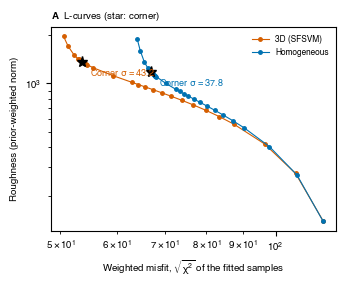

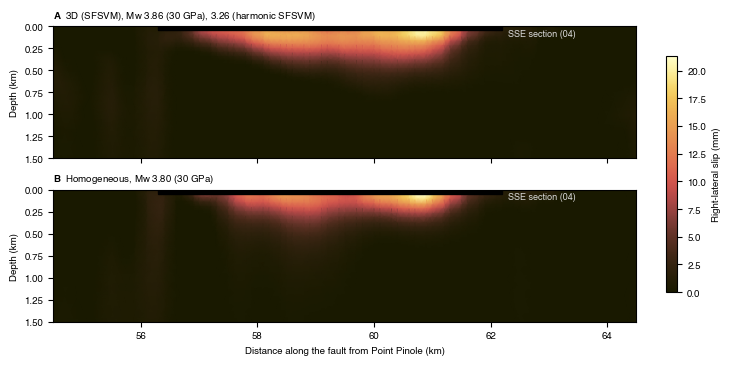

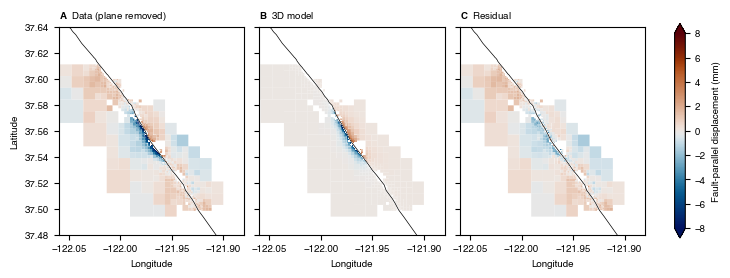

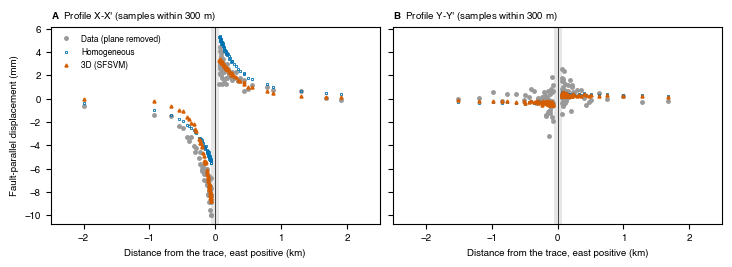

In [10]:
## [9]
lcurve_hom = pd.read_csv(os.path.join(dir_07a, "homogeneous_lcurve.csv"))


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(fig_dir, f"{name}.{ext}"), dpi=300, facecolor="white")
    print("saved", os.path.join(fig_dir, name + ".png"))


# L-curves
fig, ax = plt.subplots(figsize=(8.5 * cm, 7.0 * cm), constrained_layout=True)
for table, corner, colour, label in ((lcurve, sigma, OKABE["vermillion"], "3D (SFSVM)"),
                                     (lcurve_hom, float(lcurve_hom.corner.iloc[0]), OKABE["blue"], "Homogeneous")):
    ax.loglog(np.sqrt(table.chi2_fitted), table.roughness, "o-", color=colour, ms=2.5, lw=0.8, label=label)
    at = np.argmin(np.abs(table.sigma - corner))
    ax.loglog(np.sqrt(table.chi2_fitted.iloc[at]), table.roughness.iloc[at], "*", color="k", ms=8)
    ax.annotate(f"Corner $\\sigma$ = {corner:.1f}", (np.sqrt(table.chi2_fitted.iloc[at]), table.roughness.iloc[at]),
                textcoords="offset points", xytext=(6, -10), fontsize=6.5, color=colour)
ax.set_xlabel("Weighted misfit, $\\sqrt{\\chi^2}$ of the fitted samples")
ax.set_ylabel("Roughness (prior-weighted norm)")
ax.legend(loc="upper right")
utils.panel_title(ax, "A", "L-curves (star: corner)")
save(fig, "figS_model_lcurve")

# slip on the unrolled fault, 3D and homogeneous
triangulation = mtri.Triangulation(tents.imp_km, tents.imp_depth_km, tents.sub_faces)
fig, axes = plt.subplots(2, 1, figsize=(18.3 * cm, 9.0 * cm), sharex=True, constrained_layout=True)
vmax = float(max(slip.max(), homogeneous["slip_mm"].max()))
# the SSE section ends are thin dashed lines; each label gives the elastic structure, the dip and the key numbers
for ax, letter, values, title in ((axes[0], "A", slip,
                                   f"3D SFSVM, fault dipping {cfg.selected_dip_label}, Mw {numbers['Mw_30gpa']:.2f} (30 GPa) and {numbers['Mw_sfcvm']:.2f} "
                                   f"(SFSVM rigidity), RMS {numbers['rms_mm']:.2f} mm, depth extent {numbers['depth90_m'] / 1e3:.2f} km"),
                                  (axes[1], "B", homogeneous["slip_mm"],
                                   f"Homogeneous half-space, fault dipping {cfg.selected_dip_label}, Mw {float(homogeneous['Mw_30gpa']):.2f} (30 GPa), "
                                   f"RMS {float(homogeneous['rms_mm']):.2f} mm, depth extent {float(homogeneous['depth90_m']) / 1e3:.2f} km")):
    image = ax.tripcolor(triangulation, values, shading="gouraud", cmap=cmc.lajolla, vmin=0, vmax=vmax)
    for section_end_km in (creep_lo_km, creep_hi_km):
        ax.axvline(section_end_km, color="0.85", ls="--", lw=0.6)
    ax.set_ylim(1.5, 0)
    ax.set_xlim(54.5, 64.5)
    ax.set_ylabel("Depth (km)")
    utils.panel_title(ax, letter, title)
axes[1].set_xlabel("Distance along the fault from Point Pinole (km)")
fig.colorbar(image, ax=axes, label="Right-lateral slip (mm)", shrink=0.8)
save(fig, "figS_model_slip")

# data / model / residual maps on the quadtree blocks
block_polygons = [np.c_[lon_row, lat_row] for lon_row, lat_row in zip(model_data["block_lon"], model_data["block_lat"])]
fig, axes = plt.subplots(1, 3, figsize=(18.3 * cm, 8.0 * cm), sharex=True, sharey=True, constrained_layout=True)
limit = 8.0
for ax, letter, values, title in ((axes[0], "A", data_plane_removed_mm, "Data (plane removed)"),
                                  (axes[1], "B", model_mm, "3D model"), (axes[2], "C", residual_mm, "Residual")):
    shown = np.where(keep, values, np.nan)
    collection = PolyCollection(block_polygons, array=shown, cmap=cmc.vik, edgecolors="none")
    collection.set_clim(-limit, limit)
    ax.add_collection(collection)
    ax.plot(trace["lonlat"][:, 0], trace["lonlat"][:, 1], color="k", lw=0.5)
    ax.set_xlim(-122.06, -121.88)
    ax.set_ylim(37.48, 37.64)
    ax.set_aspect(1 / np.cos(np.deg2rad(37.56)))
    utils.panel_title(ax, letter, title)
    ax.set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(collection, ax=axes, label="Fault-parallel displacement (mm)", shrink=0.7, extend="both")
save(fig, "figS_model_fit_maps")

# across-fault profiles X-X' and Y-Y' (samples within 300 m of each line)
fig, axes = plt.subplots(1, 2, figsize=(18.3 * cm, 6.5 * cm), sharey=True, constrained_layout=True)
for ax, letter, line in ((axes[0], "A", "X"), (axes[1], "B", "Y")):
    on_line, _ = model_utils.profile_samples(model_data["sample_lon"], model_data["sample_lat"], fig2_inputs[f"prof_fp_{line}_ends"],
                                             fig2_inputs["epsg"])
    shown = on_line & keep
    order = np.argsort(signed_d_km[shown])
    d_shown = signed_d_km[shown][order]
    ax.plot(d_shown, data_plane_removed_mm[shown][order], "o", color=OKABE["grey"], ms=2.5, label="Data (plane removed)")
    ax.plot(d_shown, homogeneous["model_mm"][shown][order], "s", color=OKABE["blue"], ms=2.0, mfc="none", mew=0.6, label="Homogeneous")
    ax.plot(d_shown, model_mm[shown][order], "^", color=OKABE["vermillion"], ms=2.2, label="3D (SFSVM)")
    ax.axvline(0, color="k", lw=0.5)
    ax.axvspan(-cfg.near_trace_cut_km, cfg.near_trace_cut_km, color="0.9", lw=0)
    ax.set_xlim(-2.5, 2.5)
    ax.set_xlabel("Distance from the trace, east positive (km)")
    utils.panel_title(ax, letter, f"Profile {line}-{line}' (samples within 300 m)")
axes[0].set_ylabel("Fault-parallel displacement (mm)")
axes[0].legend(loc="upper left")
save(fig, "figS_model_profiles")

# the SFSVM shear modulus at 50 m depth and across X-X', as delivered and aligned, with the published fault dips
sys.path.insert(0, os.path.join(repo_dir, "scripts", "model_plots"))
import plot_materials                                                   # noqa: E402
plot_materials.main(paths_sfcvm["spatialdb"], fig_dir)

## [10] Monte Carlo of correlated noise

100 realisations (fixed seed) of noise drawn from the full covariance of the noise model (nugget / N^0.5 on the
diagonal plus the exponential term, `model_utils.covariance_matrix`; `model_utils.correlated_noise`), each added to the
model prediction (slip model plus fitted plane) and inverted with the same settings at the fixed corner sigma. The
spread of each number is its uncertainty from data noise (Wright 2003; Sudhaus & Jonsson 2009). The Monte Carlo mean
is printed next to the model value.

  10 realisations (3.7 min)


  20 realisations (7.3 min)


  30 realisations (11.0 min)


  40 realisations (14.5 min)


  50 realisations (18.2 min)


  60 realisations (22.0 min)


... (5 outputs left out)

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-28/figS_model_montecarlo.png


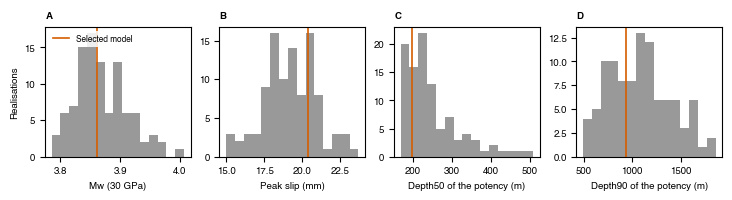

In [11]:
## [10]
t0 = time.time()
noise_cd = model_utils.covariance_matrix(np.asarray(samples.x, float), np.asarray(samples.y, float), np.asarray(samples.wgt, float),
                                         cov_p, cfg.mc_noise_nugget_power)
noise = model_utils.correlated_noise(noise_cd, cfg.mc_n_realisations, cfg.mc_seed)
prediction_mm = model_mm + plane_mm
mc_rows = []
for k in range(cfg.mc_n_realisations):
    fault_k, data_k, _ = solve_3d(sigma, vel=prediction_mm + noise[k])
    numbers_k = model_utils.tent_numbers(fault_k.slip[:, 0].copy(), data_k, tents, keep, west_near, east_near, cfg.mu_ref_pa, mu_harmonic)
    mc_rows.append(dict(realisation=k, **numbers_k))
    if k % 10 == 9:
        print(f"  {k + 1} realisations ({(time.time() - t0) / 60:.1f} min)", flush=True)
montecarlo = pd.DataFrame(mc_rows)
montecarlo.to_csv(os.path.join(out_dir, "montecarlo_realisations.csv"), index=False)
mc_keys = ["Mw_30gpa", "Mw_sfcvm", "potency_m3", "peak_slip_mm", "peak_depth_m", "depth50_m", "depth90_m", "rms_mm"]
mc_summary = pd.DataFrame([dict(quantity=key, model=numbers[key], mc_mean=montecarlo[key].mean(), mc_sd=montecarlo[key].std(ddof=1),
                                mc_p2_5=np.percentile(montecarlo[key], 2.5), mc_p97_5=np.percentile(montecarlo[key], 97.5))
                           for key in mc_keys])
mc_summary.to_csv(os.path.join(out_dir, "montecarlo_summary.csv"), index=False)
print(mc_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(18.3 * cm, 4.8 * cm), constrained_layout=True)
for ax, letter, key, label in ((axes[0], "A", "Mw_30gpa", "Mw (30 GPa)"), (axes[1], "B", "peak_slip_mm", "Peak slip (mm)"),
                               (axes[2], "C", "depth50_m", "Depth50 of the potency (m)"), (axes[3], "D", "depth90_m", "Depth90 of the potency (m)")):
    ax.hist(montecarlo[key], bins=15, color=OKABE["grey"])
    ax.axvline(numbers[key], color=OKABE["vermillion"], lw=1.2, label="Selected model")
    ax.set_xlabel(label)
    utils.panel_title(ax, letter)
axes[0].set_ylabel("Realisations")
axes[0].legend(loc="upper left")
save(fig, "figS_model_montecarlo")

## [11] Stress drop

For a long strike-slip fault that reaches the free surface, delta-sigma = (2 / pi) mu d / w (Knopoff 1958; Kanamori &
Anderson 1975, Eq. 1; `model_utils.strike_slip_stress_drop_pa`), with d the slip and w the down-dip width of the best
uniform-slip model of the fixed-depth scan (`scripts/sensitivity/depth_scan.py`, stored `depth_scan.csv`: uniform slip
from the surface to depth D over the SSE section, one amplitude plus a plane, equal weights, no smoothing; best D =
smallest RMS of the fitted samples; w = D / sin(dip)).
Check: the best row is re-solved here (`model_utils.uniform_slip_shape`, `uniform_slip_fit`) and must equal the csv.
mu at 30 GPa and at the harmonic mean of the SFSVM rigidity west and east of the fault (the area-weighted mean of
the PyLith cells beside the fault triangles of the SSE section from 0 to D on each side, then
`harmonic_mean_rigidity`).

In [12]:
## [11]
scan = pd.read_csv(cfg.archived["depth_scan"])
best = scan.loc[scan.rms_all_mm.idxmin()]
best_depth_km = float(best.D_km)
shape = model_utils.uniform_slip_shape(tents, (creep_lo_km, creep_hi_km), cfg.depth_scan_taper_km, best_depth_km)
best_slip_mm, best_residual = model_utils.uniform_slip_fit(G, shape, samples.vel.astype(float), np.asarray(samples.x, float),
                                                           np.asarray(samples.y, float), keep)
best_rms = float(np.sqrt(np.mean(best_residual[keep] ** 2)))
print(f"best D {best_depth_km:.2f} km: slip {best_slip_mm:.3f} mm here vs {best.slip_mm:.3f} in the scan; RMS {best_rms:.4f} vs {best.rms_all_mm:.4f} mm")
assert abs(best_slip_mm - best.slip_mm) < 1e-6 * best.slip_mm and abs(best_rms - best.rms_all_mm) < 1e-6, "the scan does not reproduce"
print("PASS: the best fixed-depth row reproduces")
upper = (tents.tri_depth_m <= best_depth_km * 1e3) & (tents.tri_km >= creep_lo_km) & (tents.tri_km <= creep_hi_km)
mu_west_upper = float(np.average(mu_west[upper], weights=tents.tri_area[upper]))
mu_east_upper = float(np.average(mu_east[upper], weights=tents.tri_area[upper]))
mu_harmonic_upper = float(model_utils.harmonic_mean_rigidity(mu_west_upper, mu_east_upper))
width_m = best_depth_km * 1e3 / np.sin(np.radians(cfg.selected_dip_deg))      # down-dip width of the slipping part
stress_drop = pd.DataFrame([dict(rigidity=label, mu_gpa=mu / 1e9, slip_mm=best_slip_mm, depth_m=best_depth_km * 1e3,
                                 dip_deg=cfg.selected_dip_deg, width_m=width_m,
                                 stress_drop_kpa=model_utils.strike_slip_stress_drop_pa(mu, best_slip_mm * 1e-3, width_m) / 1e3)
                            for label, mu in (("30 GPa", cfg.mu_ref_pa), ("harmonic SFSVM west/east, 0 to D", mu_harmonic_upper))])
stress_drop.to_csv(os.path.join(out_dir, "stress_drop.csv"), index=False)
print(f"SFSVM beside the fault, SSE section, 0-{best_depth_km * 1e3:.0f} m ({upper.sum()} triangles): west {mu_west_upper / 1e9:.3f}, "
      f"east {mu_east_upper / 1e9:.3f}, harmonic {mu_harmonic_upper / 1e9:.3f} GPa")
print(stress_drop.round(3).to_string(index=False))

best D 0.35 km: slip 12.827 mm here vs 12.827 in the scan; RMS 1.3245 vs 1.3245 mm
PASS: the best fixed-depth row reproduces
SFSVM beside the fault, SSE section, 0-350 m (1397 triangles): west 1.355, east 1.553, harmonic 1.447 GPa
                        rigidity  mu_gpa  slip_mm  depth_m  half_width_m  stress_drop_kpa
                          30 GPa  30.000   12.827    350.0         175.0         2198.998
harmonic SFSVM west/east, 0 to D   1.447   12.827    350.0         175.0          106.075


## [12] Products and the number registry

`selected_model.npz` holds what Fig 2 (07c) draws: the samples and their blocks, the raw data, plane, model, residual,
`keep`, the signed distance and along-strike km, the crossings steps of panel K, the slip on the tents, Mw.

In [13]:
## [12]
selected_file = os.path.join(out_dir, "selected_model.npz")
np.savez(selected_file, sample_lon=model_data["sample_lon"], sample_lat=model_data["sample_lat"], block_lon=model_data["block_lon"],
         block_lat=model_data["block_lat"], data_mm=samples.vel.copy(), plane_mm=plane_mm, model_mm=model_mm,
         data_plane_removed_mm=data_plane_removed_mm, residual_mm=residual_mm, keep=keep, signed_d_km=signed_d_km,
         sample_km_pp=sample_km_pp, crossing_km=crossing_km, data_step_mm=data_step, model_step_mm=model_step,
         step_inner_km=cfg.fig2k_inner_km, step_outer_km=cfg.fig2k_outer_km, slip_mm=slip, imp_km=tents.imp_km,
         imp_depth_km=tents.imp_depth_km, sub_faces=tents.sub_faces, imp_xyz=tents.imp_xyz, mu_harmonic_pa=mu_harmonic,
         **{k: v for k, v in numbers.items()}, run=cfg.gf_run, field_fingerprint=field_fingerprint,
         provenance=f"{notebook} {made}: {cfg.gf_run}, settings of model_config, sigma {sigma:.3f}")
mc = mc_summary.set_index("quantity")
stats = REG.sidecar("08a_selected", cfg.summary() + [comparison.to_string(index=False), model_comparison.to_string(index=False),
                                                      mc_summary.to_string(index=False), deflection.to_string(index=False),
                                                      stress_drop.to_string(index=False)]
                    + [f"{k} = {v}" for k, v in numbers.items()])
where = "M8"
REG.register("08a_n_samples_fitted", numbers["n_fitted"], "count", 0, where, "[3]", stats)
REG.register("08a_sigma", sigma, "mm", 1, where, "[5]", stats)
REG.register("08a_sigma_base_corner", sigma_base, "mm", 1, where, "[5]", stats)
REG.register("08a_mw_30gpa", numbers["Mw_30gpa"], "Mw", 2, where, "[6]", stats)
REG.register("08a_mw_harmonic", numbers["Mw_sfcvm"], "Mw", 2, where, "[6]", stats)
REG.register("08a_mu_effective_harmonic_gpa", numbers["mu_effective_gpa"], "GPa", 1, where, "[6]", stats)
REG.register("08a_potency_m3", numbers["potency_m3"], "m3", 0, where, "[6]", stats)
REG.register("08a_peak_slip_mm", numbers["peak_slip_mm"], "mm", 1, where, "[6]", stats)
REG.register("08a_peak_depth_m", numbers["peak_depth_m"], "m", 0, where, "[6]", stats)
REG.register("08a_depth50_m", numbers["depth50_m"], "m", 0, where, "[6]", stats)
REG.register("08a_depth90_m", numbers["depth90_m"], "m", 0, where, "[6]", stats)
REG.register("08a_rms_mm", numbers["rms_mm"], "mm", 2, where, "[6]", stats)
REG.register("08a_rms_west500_mm", numbers["rms_west_mm"], "mm", 2, where, "[6]", stats)
REG.register("08a_rms_east500_mm", numbers["rms_east_mm"], "mm", 2, where, "[6]", stats)
REG.register("08a_band_step_mean_mm", numbers["band_step_mean_mm"], "mm", 2, where, "[6]", stats)
REG.register("08a_band_step_rms_mm", numbers["band_step_rms_mm"], "mm", 2, where, "[6]", stats)
for key, tag, units, precision in (("Mw_30gpa", "mw_30gpa", "Mw", 3), ("Mw_sfcvm", "mw_harmonic", "Mw", 3),
                                   ("potency_m3", "potency_m3", "m3", 0), ("peak_slip_mm", "peak_slip_mm", "mm", 2),
                                   ("depth50_m", "depth50_m", "m", 0), ("depth90_m", "depth90_m", "m", 0)):
    REG.register(f"08a_mc_{tag}_sd", mc.loc[key, "mc_sd"], units, precision, where, "[10]", stats)
    REG.register(f"08a_mc_{tag}_p2_5", mc.loc[key, "mc_p2_5"], units, precision, where, "[10]", stats)
    REG.register(f"08a_mc_{tag}_p97_5", mc.loc[key, "mc_p97_5"], units, precision, where, "[10]", stats)
for _, row in deflection[deflection.far_band == "selected"].iterrows():
    tag = {"Data (3D model's plane removed)": "data", "3D model": "model", "Data (homogeneous model's plane removed)": "data_homplane",
           "Homogeneous model": "hom"}[row.field]
    REG.register(f"08a_deflection_{tag}_west_mm", row.west_mm, "mm", 2, "M7", "[8b]", stats)
    REG.register(f"08a_deflection_{tag}_east_mm", row.east_mm, "mm", 2, "M7", "[8b]", stats)
REG.register("08a_stress_drop_depth_m", best_depth_km * 1e3, "m", 0, where, "[11]", stats)
REG.register("08a_stress_drop_slip_mm", best_slip_mm, "mm", 1, where, "[11]", stats)
REG.register("08a_stress_drop_mu_harmonic_gpa", mu_harmonic_upper / 1e9, "GPa", 2, where, "[11]", stats)
REG.register("08a_stress_drop_width_m", width_m, "m", 0, where, "[11]", stats)
REG.register("08a_stress_drop_30gpa_mpa", stress_drop.stress_drop_kpa.iloc[0] / 1e3, "MPa", 2, where, "[11]", stats)
REG.register("08a_stress_drop_harmonic_kpa", stress_drop.stress_drop_kpa.iloc[1], "kPa", 0, where, "[11]", stats)
REG.render()
print(f"wrote {selected_file}")

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/08a_3d_model/08a_selected_stats.txt
  registered 08a_n_samples_fitted = 1787 count  -> M8


  registered 08a_sigma = 43.2 mm  -> M8


  registered 08a_sigma_base_corner = 43.8 mm  -> M8
  registered 08a_mw_30gpa = 3.86 Mw  -> M8


  registered 08a_mw_harmonic = 3.26 Mw  -> M8


  registered 08a_mu_effective_harmonic_gpa = 3.7 GPa  -> M8
  registered 08a_potency_m3 = 25997 m3  -> M8


  registered 08a_peak_slip_mm = 20.4 mm  -> M8


... (23 outputs left out)

  registered 08a_stress_drop_slip_mm = 12.8 mm  -> M8


  registered 08a_stress_drop_mu_harmonic_gpa = 1.45 GPa  -> M8
  registered 08a_stress_drop_30gpa_mpa = 2.20 MPa  -> M8


  registered 08a_stress_drop_harmonic_mpa = 0.11 MPa  -> M8


  NB: retired notebook 07b_uniform_model_tests is not in the repo any more (its keys are retired either way)
  NB: retired notebook 08b_3d_model_tests is not in the repo any more (its keys are retired either way)
  NB: retired notebook 08c_3d_model_sensitivity is not in the repo any more (its keys are retired either way)
  01_prep_inputs: its latest run registered no numbers (sidecar newer than its last registry row); its keys are retired
  07b_uniform_model_tests: retired from the paper (TulePond_filepaths.retired_notebooks); its 26 keys are listed as RETIRED
  08b_3d_model_tests: retired from the paper (TulePond_filepaths.retired_notebooks); its 113 keys are listed as RETIRED
  08c_3d_model_sensitivity: retired from the paper (TulePond_filepaths.retired_notebooks); its 0 keys are listed as RETIRED
Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt
wrote /Users/dlindsay/work/proj_TulePond_DISP/outputs/08a_3d_model/selected_model.npz
